*This notebook was developed by Kabelo Tsiane for the DESC CL_Cosmo_Pipeline team.*

# This notebook presents the cluster pipeline outputs for stacked $\Delta\Sigma$ and $g_t$ profiles on Rubin Data Preview 2 (DP2).

It is meant to be run independently. You must run the pipeline from the terminal first, see below.

The pipeline goes from the cluster catalog (a CSV file) and a DP2 shear catalog to stacked cluster lensing profiles, in one run. There is one pipeline per shear catalog; you choose the shear catalog by choosing which pipeline to run. Section 5 compares the profiles from the different shear catalogs.

___

In [66]:
import os
import sys
from pprint import pprint

import ceci
import h5py

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import yaml
from IPython.display import Image

Make sure to change your path in the next cell that leads to your TXPipe directory. The DP2 pipeline files are in `examples/dp2/Cluster_pipelines/`.

In [67]:
# user specific paths -- NERSC example
#my_txpipe_dir = "/global/cfs/cdirs/m1727/kabelo/TXPipe"
my_txpipe_dir = "/pscratch/sd/y/yyzhang/desc/TXPipe"

os.chdir(my_txpipe_dir)

# TXPipe is used from its source directory, not installed
sys.path.insert(0, my_txpipe_dir)
import txpipe

___

# 1 - Launching the pipeline

There is one pipeline (and one submission script) per DP2 shear catalog. Both catalogs come from the DESC data registry, and both are cut with the DESC wide-field metadetect mask (registry id 151, `rubin_dp2_wide_metadetect_mask` 0.2.0):

| shear catalog | registry id | pipeline file | submission script |
|---|---|---|---|
| Rubin metadetect | 137 | `examples/dp2/Cluster_pipelines/pipeline-dp2-CL-rubin-nersc.yml` | `examples/dp2/Cluster_pipelines/dp2-rubin-nersc.sub` |
| Sheldon (DESC) metadetect | 147 | `examples/dp2/Cluster_pipelines/pipeline-dp2-CL-sheldon-nersc.yml` | `examples/dp2/Cluster_pipelines/dp2-sheldon-nersc.sub` |

Everything else (the cluster catalog, the photo-z settings, the cluster bins and the profile settings) is the same for both, and lives in one config file, `config-dp2-CL.yml`.

As of 12 Oct 2026 these masks, and catalogs, are constantly changing. See guidance on [confluence](https://confluence.slac.stanford.edu/pages/viewpage.action?pageId=726185111&spaceKey=LSSTDESC&title=Data%2BPreview%2B2). 

In [68]:
shear_catalog = "rubin"   # or "sheldon": the shear catalog whose pipeline we look at in Sections 2-4
pipeline_dir = "examples/dp2/Cluster_pipelines"
pipeline_file = f"{pipeline_dir}/pipeline-dp2-CL-gglens-{shear_catalog}-nersc.yml"

# 3 - Producing and looking at the pipeline diagram

Here we run the pipeline in "dry-run" mode, to check that it can run and to produce a pipeline diagram in png.

In [69]:
# Read the appropriate pipeline configuration, and ask for a flow-chart.
flowchart_file = f"CL_dp2_TxPipe2pt_pipeline_{shear_catalog}.png"

pipeline_config = ceci.Pipeline.build_config(pipeline_file, flow_chart=flowchart_file, dry_run=True)

# Run the flow-chart pipeline
ceci.run_pipeline(pipeline_config);

The red ellipses are the stages, the yellow boxes the input files, and the blue boxes the output files. The cluster catalog (left) and the shear catalog (right) are processed separately and meet in the cluster-shear stages.

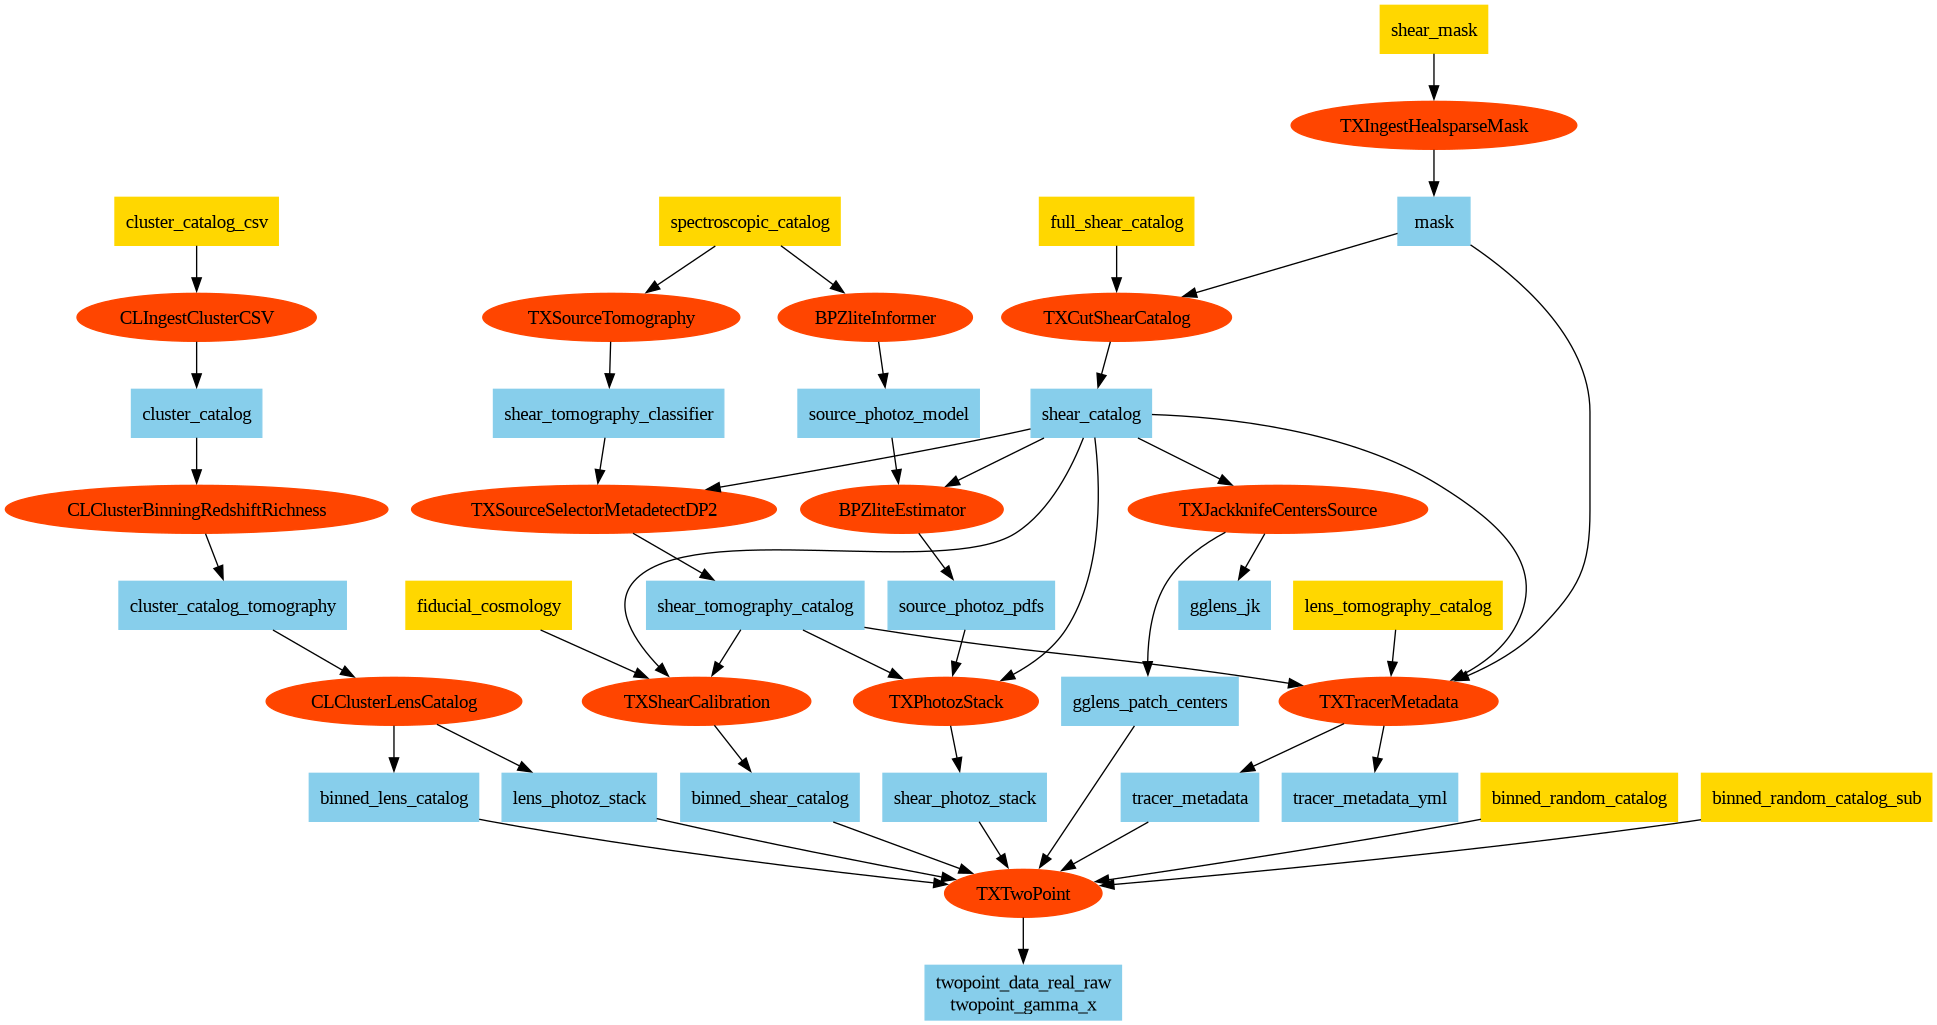

In [70]:
Image(flowchart_file)

___

# 4 - Opening and looking at the outputs

### **Open the pipeline file to load correct input/output file names**

/pscratch/sd/y/yyzhang/dp2/outputs/rubin


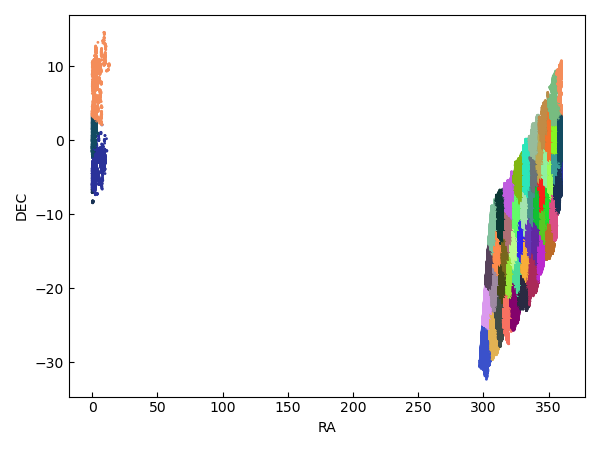

In [71]:
with open(pipeline_file, "r") as file:
    pipeline_content = yaml.safe_load(file)
output_dir = pipeline_content["output_dir"]
print(output_dir)
Image(output_dir+'/gglens_jk.png')

### **Open the output**

There is one output file per profile type, in its own sub-directory of the output directory: `delta_sigma/cluster_profiles.pkl` and `gt/cluster_profiles.pkl`.

(18, 18) [6.98728855e-05 1.62535361e-05 1.54143204e-05 1.91997908e-06
 1.36039118e-06 1.69695389e-06] [ 6.53259590e-03  2.77868090e-03  3.31923750e-04 -3.58150215e-06
 -9.17088625e-05  3.70751132e-05]
(18, 18) [1.59655787e-05 2.49879424e-06 4.64281471e-06 3.77203238e-07
 3.02222523e-07 6.29281337e-07] [ 6.53259590e-03  2.77868090e-03  3.31923750e-04 -3.58150215e-06
 -9.17088625e-05  3.70751132e-05]
(18, 18) [6.57295425e-05 3.00100861e-05 4.62694721e-06 3.24552408e-06
 2.70848804e-06 7.89197451e-08] [ 6.53259590e-03  2.77868090e-03  3.31923750e-04 -3.58150215e-06
 -9.17088625e-05  3.70751132e-05]


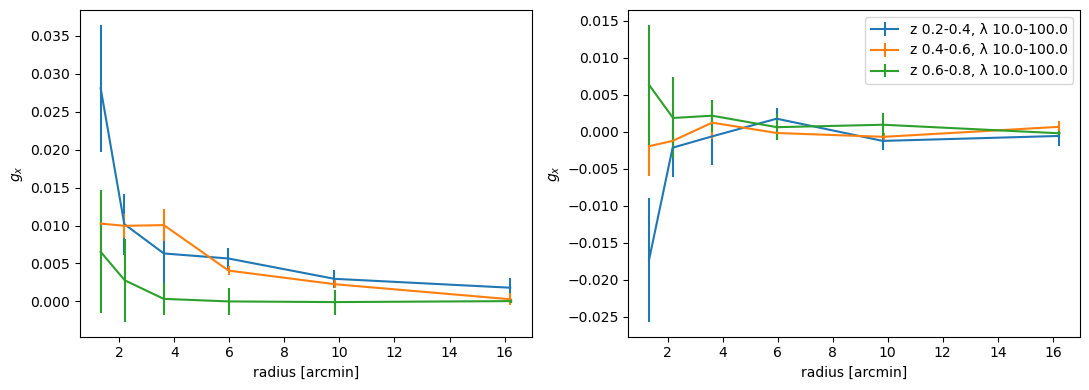

In [72]:
import sacc

sacc_data_gt = sacc.Sacc.load_fits(output_dir + f"/twopoint_data_real_raw.sacc")
sacc_data_gx = sacc.Sacc.load_fits(output_dir + f"/twopoint_gamma_x.sacc")
#print(sacc_data_gx.get_data_types())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))


with h5py.File("/pscratch/sd/y/yyzhang/dp2/outputs/rubin/binned_lens_catalog.hdf5") as f:
    lens_map = {f"lens_{k}": dict(f[f"lens/bin_{k}"].attrs)
                for k in range(f["lens"].attrs["nbin_lens"])}

lens_ind = 0
for src, lens in sacc_data_gt.get_tracer_combinations("galaxy_shearDensity_xi_t"):
    #print(src, lens)
    a = lens_map[lens]
    theta, gt = sacc_data_gt.get_theta_xi("galaxy_shearDensity_xi_t", src, lens)
    #print(lens, f"z {a['z_min']}-{a['z_max']}, λ {a['rich_min']}-{a['rich_max']}")

    if sacc_data_gt.has_covariance():
      # Extract the dense 2D covariance matrix array
      cov_matrix = sacc_data_gt.covariance.covmat
      cov_diag = np.diag(cov_matrix)[lens_ind * len(gt): (lens_ind+1) * len(gt)]
      #print(cov_matrix.shape, cov_diag, gt)

    ax=axes[0]
    ax.errorbar(theta, gt, yerr = np.sqrt(cov_diag), label = f"z {a['z_min']}-{a['z_max']}, λ {a['rich_min']}-{a['rich_max']}")
    ax.set_xlabel('radius [arcmin]')
    ax.set_ylabel('$g_x$')
    lens_ind = lens_ind + 1
    
lens_ind = 0
for src, lens in sacc_data_gx.get_tracer_combinations("galaxy_shearDensity_xi_x"):
    #print(sacc_data_gx.has_covariance())
    a = lens_map[lens]
    theta, gx = sacc_data_gx.get_theta_xi("galaxy_shearDensity_xi_x", src, lens)

    if sacc_data_gt.has_covariance():
      # Extract the dense 2D covariance matrix array
      cov_matrix = sacc_data_gt.covariance.covmat
      cov_diag = np.diag(cov_matrix)[lens_ind * len(gt): (lens_ind+1) * len(gt)]
      print(cov_matrix.shape, cov_diag, gt)

    ax=axes[1]
    ax.errorbar(theta, gx, yerr = np.sqrt(cov_diag), label = f"z {a['z_min']}-{a['z_max']}, λ {a['rich_min']}-{a['rich_max']}")
    ax.set_xlabel('radius [arcmin]')
    ax.set_ylabel('$g_x$')
    lens_ind = lens_ind + 1
plt.legend(loc = 0)
plt.tight_layout()
    

# Examine the DeltaSigma measurements through TXdeltasigma

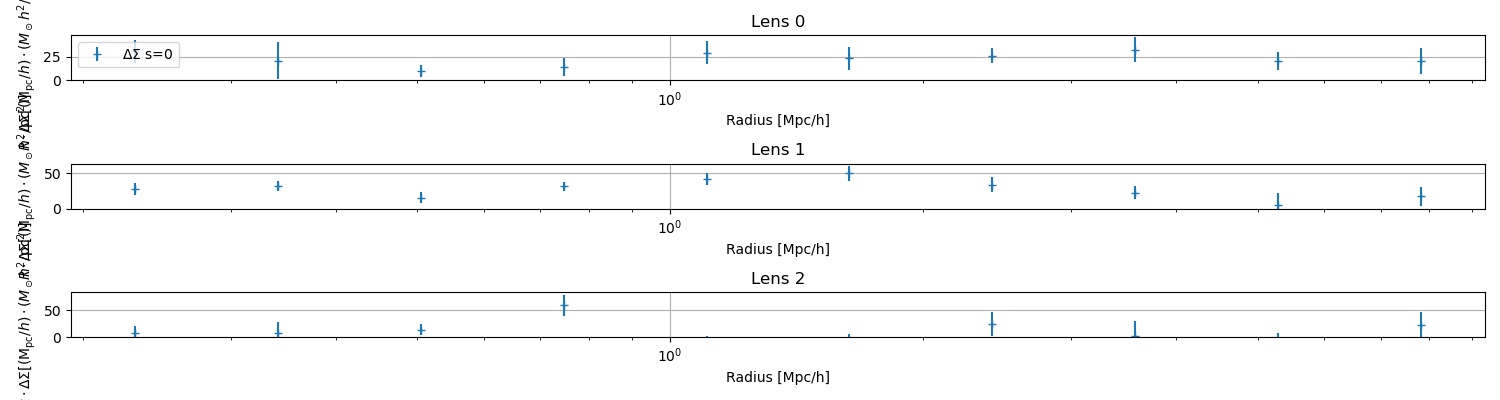

In [73]:
Image(output_dir + f"/delta_sigma_plot.png")

['galaxy_shearDensity_deltasigma']
source_0 lens_0
source_0 lens_1
source_0 lens_2
source_1 lens_0
source_1 lens_1
source_1 lens_2


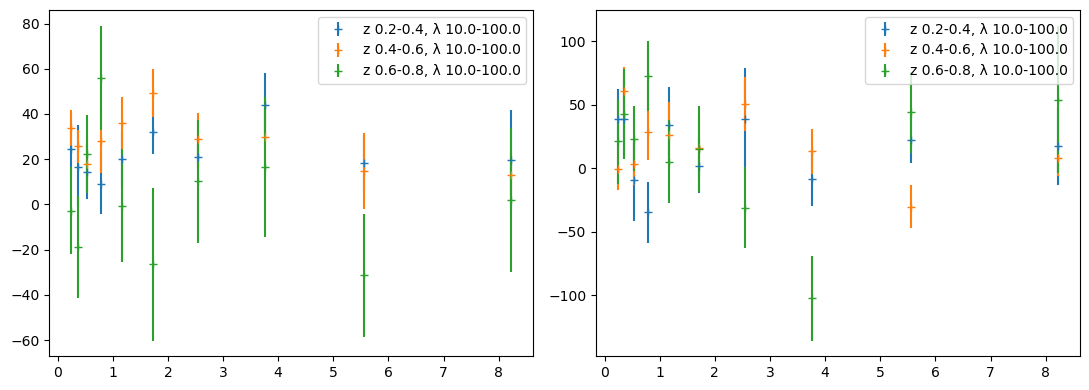

In [77]:
import sacc

sacc_data = sacc.Sacc.load_hdf5("/pscratch/sd/y/yyzhang/dp2/outputs_ds/rubin/delta_sigma.sacc")
print(sacc_data.get_data_types())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
with h5py.File("/pscratch/sd/y/yyzhang/dp2/outputs_ds/rubin/binned_lens_catalog.hdf5") as f:
    lens_map = {f"lens_{k}": dict(f[f"lens/bin_{k}"].attrs)
                for k in range(f["lens"].attrs["nbin_lens"])}

for src, lens in sacc_data.get_tracer_combinations("galaxy_shearDensity_deltasigma"):
    print(src, lens)
    #print(sacc_data_gx.has_covariance())
    a = lens_map[lens]
    if src == 'source_0':
        ax = axes[0]
    else:
        ax = axes[1]

    x = sacc_data.get_tag("rp", tracers=(src, lens))
    x = np.array(x)
    y = sacc_data.get_mean(tracers=(src, lens))

    if sacc_data.has_covariance():
        cov = sacc_data.covariance.dense
    else:
        cov = None
    
    if cov is not None:
        index = sacc_data.indices(tracers=(src, lens))
        cov_block = cov[index][:, index]
        error = np.sqrt(np.diag(cov_block))
        ax.errorbar(x, y * x, yerr=error * x, fmt="+",
                        label = f"z {a['z_min']}-{a['z_max']}, λ {a['rich_min']}-{a['rich_max']}")

axes[0].legend(loc = 0)
axes[1].legend(loc = 0)
plt.tight_layout()
    